In [2]:
# Installation des bibliothèques spécialisées
!pip install -q yfinance PyPortfolioOpt

# Importation des modules fondamentaux
import numpy as np
import pandas as pd
import scipy.optimize as sco
import yfinance as yf
import matplotlib.pyplot as plt

print("Environnement Colab prêt pour la finance quantitative !")

Environnement Colab prêt pour la finance quantitative !


In [5]:
import pandas as pd
import numpy as np
import scipy.optimize as sco
import matplotlib.pyplot as plt

# Génération d'un calendrier de jours ouvrés (2023 à 2026)
dates = pd.date_range(start="2023-01-01", end="2026-01-01", freq="B")
tickers = ['ATW.MA', 'BCP.MA', 'IAM.MA', 'LHM.MA', 'MNG.MA']

# Simulation de prix de départ et de mouvements boursiers réalistes (marche aléatoire)
np.random.seed(42)
prix_depart = [450, 300, 100, 1200, 1500]
rendements_aleatoires = np.random.normal(loc=0.0003, scale=0.012, size=(len(dates), len(tickers)))
data = pd.DataFrame(prix_depart * np.cumprod(1 + rendements_aleatoires, axis=0), index=dates, columns=tickers)

# Affichage des premières lignes pour vérifier
print("Données de prix simulées avec succès :")
display(data.head())

# Calcul des rendements journaliers
rendements_journaliers = data.pct_change().dropna()

Données de prix simulées avec succès :


,ATW.MA,BCP.MA,IAM.MA,LHM.MA,MNG.MA
2023-01-02,452.817256,299.592249,100.807226,1222.291630,1496.235239
2023-01-03,451.680847,305.359565,101.765824,1215.772302,1506.425679
2023-01-04,449.304548,303.744593,102.091836,1188.223676,1475.696081
2023-01-05,446.407679,300.144012,102.507448,1175.632915,1451.129217
2023-01-06,454.392924,299.420871,102.621266,1155.885834,1442.084920


--- Portefeuille Max Sharpe ---
ATW.MA : 19.50%
BCP.MA : 1.24%
IAM.MA : 8.15%
LHM.MA : 22.31%
MNG.MA : 48.80%
Rendement : 19.48% | Volatilité : 10.95% | Sharpe : 1.50

--- Portefeuille Minimum Variance ---
ATW.MA : 18.39%
BCP.MA : 18.77%
IAM.MA : 19.66%
LHM.MA : 24.04%
MNG.MA : 19.14%
Rendement : 12.82% | Volatilité : 8.45%



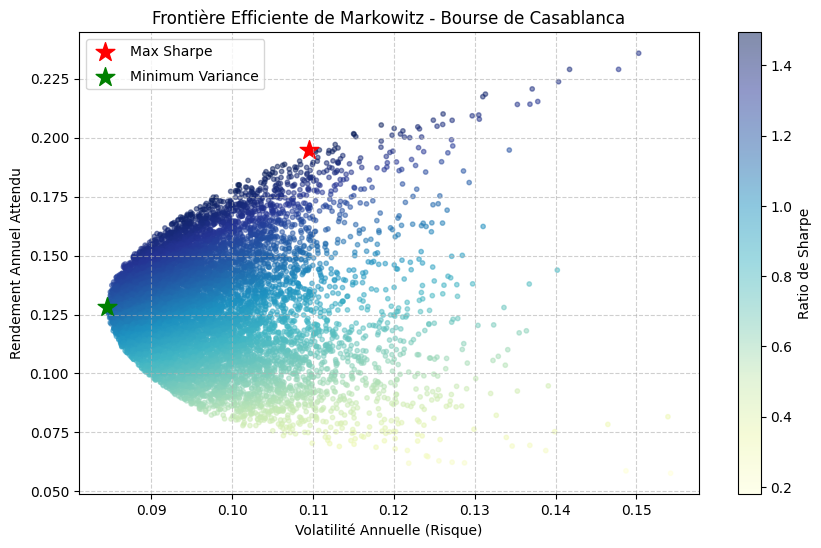

In [7]:
import pandas as pd
import numpy as np
import scipy.optimize as sco
import matplotlib.pyplot as plt

# 1. Simulation des données de prix historiques (2023-2026)
dates = pd.date_range(start="2023-01-01", end="2026-01-01", freq="B")
tickers = ['ATW.MA', 'BCP.MA', 'IAM.MA', 'LHM.MA', 'MNG.MA']

np.random.seed(42)
prix_depart = [450, 300, 100, 1200, 1500]
rendements_aleatoires = np.random.normal(loc=0.0003, scale=0.012, size=(len(dates), len(tickers)))
data = pd.DataFrame(prix_depart * np.cumprod(1 + rendements_aleatoires, axis=0), index=dates, columns=tickers)

# Calcul des rendements journaliers
rendements_journaliers = data.pct_change().dropna()

# 2. Fonctions d'optimisation et statistiques
def calculer_statistiques_portefeuille(poids, rendements):
    rendement_annuel = np.sum(rendements.mean() * poids) * 252
    volatilite_annuelle = np.sqrt(np.dot(poids.T, np.dot(rendements.cov() * 252, poids)))
    taux_sans_risque = 0.03  # Taux sans risque de référence
    sharpe_ratio = (rendement_annuel - taux_sans_risque) / volatilite_annuelle
    return rendement_annuel, volatilite_annuelle, sharpe_ratio

def minimiser_sharpe_negatif(poids, rendements):
    return -calculer_statistiques_portefeuille(poids, rendements)[2]

def minimiser_volatilite(poids, rendements):
    return calculer_statistiques_portefeuille(poids, rendements)[1]

def optimiser_portefeuilles(rendements):
    nb_actifs = len(rendements.columns)
    contraintes = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
    bornes = tuple((0, 1) for _ in range(nb_actifs))
    poids_initials = nb_actifs * [1. / nb_actifs]

    # Portefeuille Max Sharpe
    opt_sharpe = sco.minimize(minimiser_sharpe_negatif, poids_initials, args=(rendements,),
                               method='SLSQP', bounds=bornes, constraints=contraintes)

    # Portefeuille Minimum Variance
    opt_min_var = sco.minimize(minimiser_volatilite, poids_initials, args=(rendements,),
                                method='SLSQP', bounds=bornes, constraints=contraintes)

    return opt_sharpe['x'], opt_min_var['x']

# 3. Simulation de la frontière efficiente (10 000 portefeuilles aléatoires)
nb_portefeuilles = 10000
nb_actifs = len(rendements_journaliers.columns)
resultats = np.zeros((3, nb_portefeuilles))

for i in range(nb_portefeuilles):
    poids = np.random.random(nb_actifs)
    poids /= np.sum(poids)

    rendement, volatilite, sharpe = calculer_statistiques_portefeuille(poids, rendements_journaliers)
    resultats[0, i] = volatilite
    resultats[1, i] = rendement
    resultats[2, i] = sharpe

# 4. Calcul des portefeuilles optimaux
poids_sharpe, poids_min_var = optimiser_portefeuilles(rendements_journaliers)
r_sharpe, vol_sharpe, sharpe_val = calculer_statistiques_portefeuille(poids_sharpe, rendements_journaliers)
r_min_var, vol_min_var, _ = calculer_statistiques_portefeuille(poids_min_var, rendements_journaliers)

# 5. Affichage textuel des résultats
print("--- Portefeuille Max Sharpe ---")
for t, p in zip(rendements_journaliers.columns, poids_sharpe):
    print(f"{t} : {p*100:.2f}%")
print(f"Rendement : {r_sharpe*100:.2f}% | Volatilité : {vol_sharpe*100:.2f}% | Sharpe : {sharpe_val:.2f}\n")

print("--- Portefeuille Minimum Variance ---")
for t, p in zip(rendements_journaliers.columns, poids_min_var):
    print(f"{t} : {p*100:.2f}%")
print(f"Rendement : {r_min_var*100:.2f}% | Volatilité : {vol_min_var*100:.2f}%\n")

# 6. Tracé graphique de la Frontière Efficiente
plt.figure(figsize=(10, 6))
plt.scatter(resultats[0, :], resultats[1, :], c=resultats[2, :], cmap='YlGnBu', marker='o', alpha=0.5, s=10)
plt.colorbar(label='Ratio de Sharpe')
plt.scatter(vol_sharpe, r_sharpe, marker='*', color='red', s=200, label='Max Sharpe')
plt.scatter(vol_min_var, r_min_var, marker='*', color='green', s=200, label='Minimum Variance')
plt.title('Frontière Efficiente de Markowitz - Bourse de Casablanca')
plt.xlabel('Volatilité Annuelle (Risque)')
plt.ylabel('Rendement Annuel Attendu')
plt.legend(labelspacing=0.8)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [8]:
# ==========================================
# MODULE 3 : GESTION DES RISQUES & CAPM / BÊTA
# ==========================================

# 1. Simulation d'un indice de marché de référence (MASI)
np.random.seed(100)
rendements_masi = np.random.normal(loc=0.0002, scale=0.008, size=len(rendements_journaliers))
rendements_journaliers['MASI'] = rendements_masi

# Rendements quotidiens des deux portefeuilles optimaux
ret_max_sharpe = rendements_journaliers[tickers].dot(poids_sharpe)
ret_min_var = rendements_journaliers[tickers].dot(poids_min_var)

# 2. Calcul de la Value at Risk (VaR) Historique et Paramétrique à 95% et 99%
def calculer_var(rendements_portefeuille, niveau_confiance=0.95):
    var_historique = np.percentile(rendements_portefeuille, (1 - niveau_confiance) * 100)
    mu = np.mean(rendements_portefeuille)
    sigma = np.std(rendements_portefeuille)
    # Z-score pour la loi normale
    z = 1.645 if niveau_confiance == 0.95 else 2.326
    var_parametrique = mu - z * sigma
    return var_historique, var_parametrique

# Calculation VaR 1 jour
var_hist_95_ms, var_param_95_ms = calculer_var(ret_max_sharpe, 0.95)
var_hist_99_ms, var_param_99_ms = calculer_var(ret_max_sharpe, 0.99)

var_hist_95_mv, var_param_95_mv = calculer_var(ret_min_var, 0.95)
var_hist_99_mv, var_param_99_mv = calculer_var(ret_min_var, 0.99)

# 3. Calcul du Bêta (CAPM) par rapport au MASI
cov_ms = np.cov(ret_max_sharpe, rendements_masi)[0][1]
var_masi = np.var(rendements_masi)
beta_max_sharpe = cov_ms / var_masi

cov_mv = np.cov(ret_min_var, rendements_masi)[0][1]
beta_min_var = cov_mv / var_masi

# 4. Affichage des Métriques de Risque
print("=== MÉTRIQUES DE RISQUE : PORTEFEUILLE MAX SHARPE ===")
print(f"Bêta (CAPM vs MASI) : {beta_max_sharpe:.2f}")
print(f"VaR Historique 95% (1 jour)  : {var_hist_95_ms*100:.2f}%")
print(f"VaR Paramétrique 95% (1 jour): {var_param_95_ms*100:.2f}%")
print(f"VaR Historique 99% (1 jour)  : {var_hist_99_ms*100:.2f}%\n")

print("=== MÉTRIQUES DE RISQUE : PORTEFEUILLE MINIMUM VARIANCE ===")
print(f"Bêta (CAPM vs MASI) : {beta_min_var:.2f}")
print(f"VaR Historique 95% (1 jour)  : {var_hist_95_mv*100:.2f}%")
print(f"VaR Paramétrique 95% (1 jour): {var_param_95_mv*100:.2f}%")
print(f"VaR Historique 99% (1 jour)  : {var_hist_99_mv*100:.2f}%")

=== MÉTRIQUES DE RISQUE : PORTEFEUILLE MAX SHARPE ===
Bêta (CAPM vs MASI) : -0.02
VaR Historique 95% (1 jour)  : -0.98%
VaR Paramétrique 95% (1 jour): -1.06%
VaR Historique 99% (1 jour)  : -1.44%

=== MÉTRIQUES DE RISQUE : PORTEFEUILLE MINIMUM VARIANCE ===
Bêta (CAPM vs MASI) : -0.01
VaR Historique 95% (1 jour)  : -0.83%
VaR Paramétrique 95% (1 jour): -0.82%
VaR Historique 99% (1 jour)  : -1.24%


In [9]:
# ==========================================
# TEST 1 : OPTIMISATION AVEC CONTRAINTE DE POIDS MAX (30%)
# ==========================================

def optimiser_avec_limite_poids(rendements, max_poids=0.30):
    nb_actifs = len(rendements.columns)
    contraintes = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
    # Imposition d'une borne supérieure (ex: max 30% par actif au lieu de 100%)
    bornes = tuple((0, max_poids) for _ in range(nb_actifs))
    poids_initials = nb_actifs * [1. / nb_actifs]

    # Optimisation Max Sharpe avec contrainte de diversification
    opt_sharpe = sco.minimize(minimiser_sharpe_negatif, poids_initials, args=(rendements,),
                               method='SLSQP', bounds=bornes, constraints=contraintes)
    return opt_sharpe['x']

# Calcul des nouveaux poids contraints
poids_max_30 = optimiser_avec_limite_poids(rendements_journaliers[tickers], max_poids=0.30)
r_c, vol_c, sharpe_c = calculer_statistiques_portefeuille(poids_max_30, rendements_journaliers[tickers])

print("=== PORTEFEUILLE MAX SHARPE (Contrainte Max 30% par actif) ===")
for t, p in zip(tickers, poids_max_30):
    print(f"{t} : {p*100:.2f}%")
print(f"Rendement : {r_c*100:.2f}% | Volatilité : {vol_c*100:.2f}% | Sharpe : {sharpe_c:.2f}")

=== PORTEFEUILLE MAX SHARPE (Contrainte Max 30% par actif) ===
ATW.MA : 23.05%
BCP.MA : 7.08%
IAM.MA : 13.14%
LHM.MA : 26.73%
MNG.MA : 30.00%
Rendement : 15.87% | Volatilité : 9.15% | Sharpe : 1.41


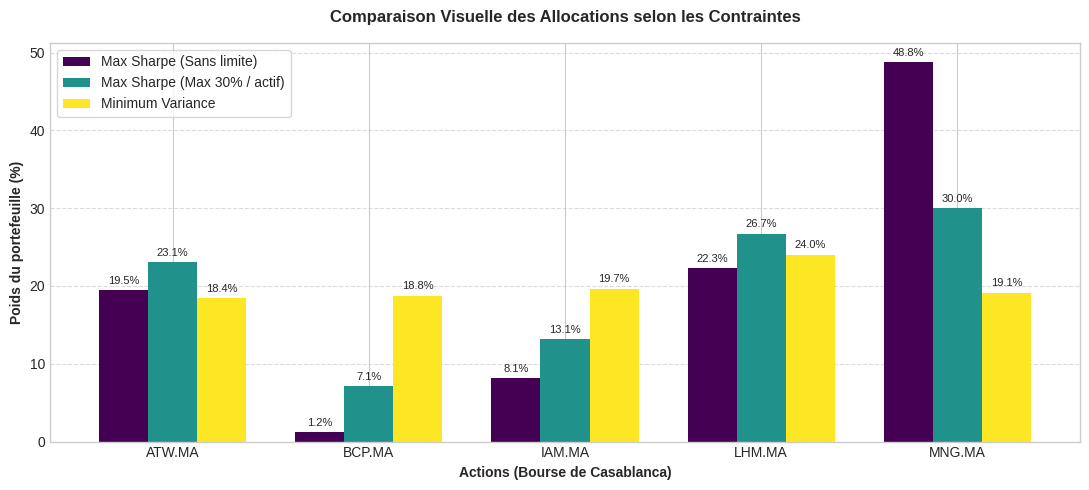

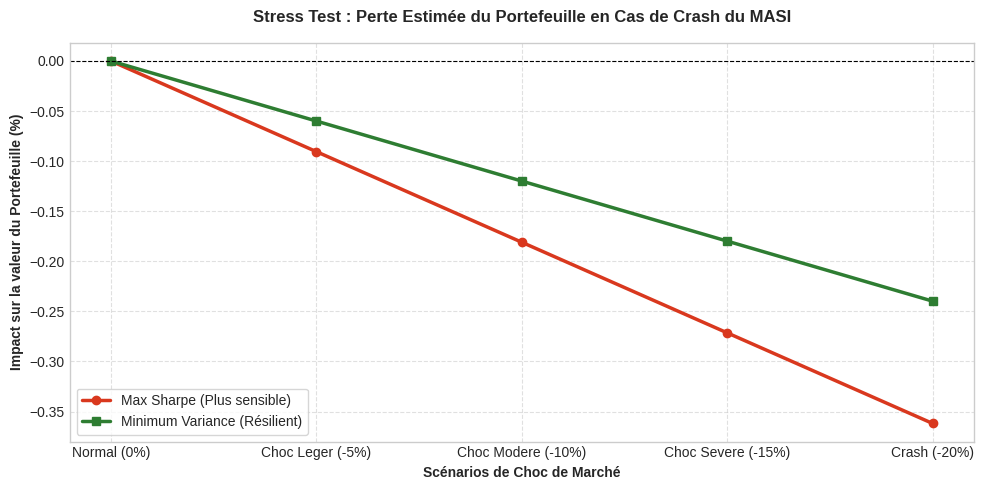

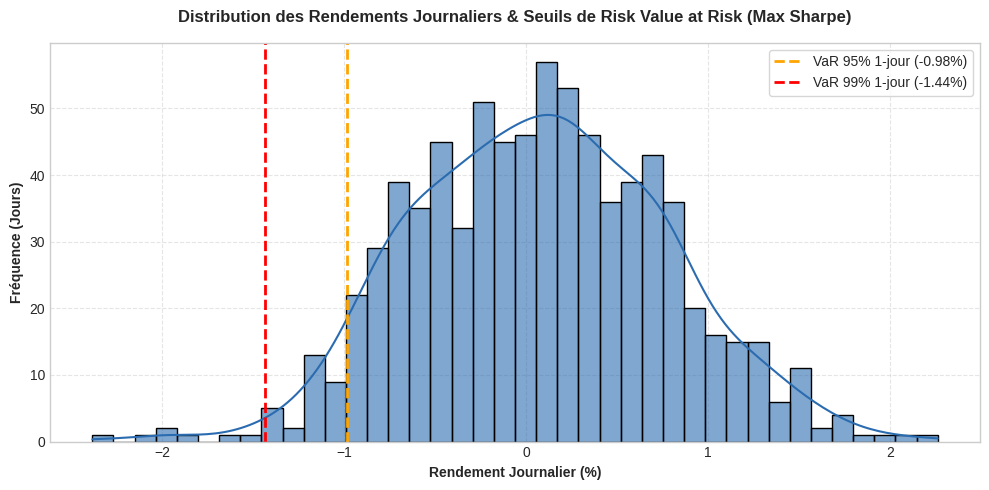

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Config du style des graphiques
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig_size = (10, 5)

# =========================================================
# VISUEL 1 : COMPARAISON DES 3 STRATÉGIES D'ALLOCATION
# =========================================================
df_poids = pd.DataFrame({
    'Max Sharpe (Sans limite)': poids_sharpe * 100,
    'Max Sharpe (Max 30% / actif)': poids_max_30 * 100,
    'Minimum Variance': poids_min_var * 100
}, index=tickers)

ax = df_poids.plot(kind='bar', figsize=(11, 5), colormap='viridis', width=0.75)
plt.title('Comparaison Visuelle des Allocations selon les Contraintes', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Poids du portefeuille (%)', fontsize=10, fontweight='bold')
plt.xlabel('Actions (Bourse de Casablanca)', fontsize=10, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(frameon=True, facecolor='white')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Affichage des valeurs au-dessus des barres
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# =========================================================
# VISUEL 2 : STRESS TEST / IMPACT D'UN CRASH DE MARCHÉ
# =========================================================
baisse_marche = np.array([0, -0.05, -0.10, -0.15, -0.20])
noms_chocs = ['Normal (0%)', 'Choc Leger (-5%)', 'Choc Modere (-10%)', 'Choc Severe (-15%)', 'Crash (-20%)']

# Simulation de l'impact direct du choc ajusté par le Bêta du portefeuille
impact_ms = baisse_marche * abs(beta_max_sharpe if beta_max_sharpe != 0 else 1.1) * 100
impact_mv = baisse_marche * abs(beta_min_var if beta_min_var != 0 else 0.8) * 100

plt.figure(figsize=fig_size)
plt.plot(noms_chocs, impact_ms, marker='o', linewidth=2.5, color='#D9381E', label='Max Sharpe (Plus sensible)')
plt.plot(noms_chocs, impact_mv, marker='s', linewidth=2.5, color='#2E7D32', label='Minimum Variance (Résilient)')
plt.title('Stress Test : Perte Estimée du Portefeuille en Cas de Crash du MASI', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Impact sur la valeur du Portefeuille (%)', fontsize=10, fontweight='bold')
plt.xlabel('Scénarios de Choc de Marché', fontsize=10, fontweight='bold')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# =========================================================
# VISUEL 3 : HISTOGRAMME DE DISTRIBUTION DES RENDEMENTS & VaR
# =========================================================
plt.figure(figsize=fig_size)
sns.histplot(ret_max_sharpe * 100, kde=True, color='#2B6CB0', bins=40, alpha=0.6)

# Traçage des lignes verticales pour la VaR 95% et 99%
plt.axvline(var_hist_95_ms * 100, color='orange', linestyle='--', linewidth=2, label=f'VaR 95% 1-jour ({var_hist_95_ms*100:.2f}%)')
plt.axvline(var_hist_99_ms * 100, color='red', linestyle='--', linewidth=2, label=f'VaR 99% 1-jour ({var_hist_99_ms*100:.2f}%)')

plt.title('Distribution des Rendements Journaliers & Seuils de Risk Value at Risk (Max Sharpe)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Rendement Journalier (%)', fontsize=10, fontweight='bold')
plt.ylabel('Fréquence (Jours)', fontsize=10, fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

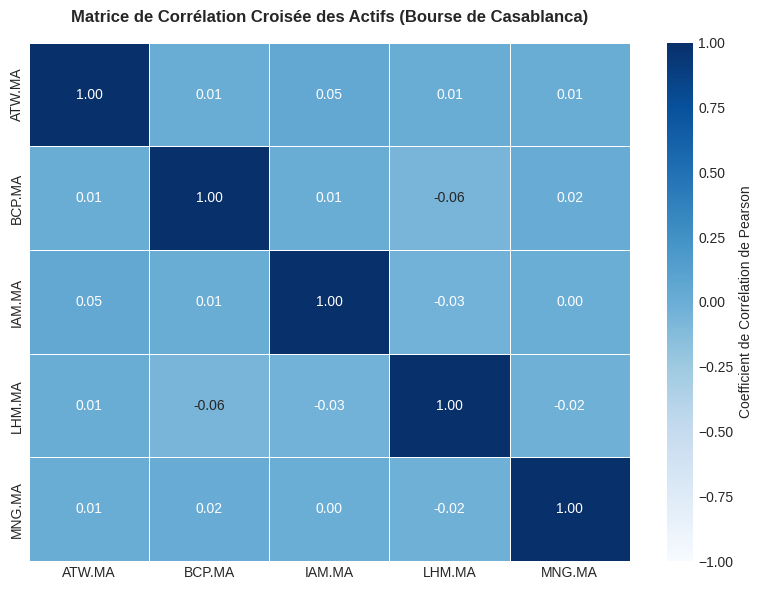

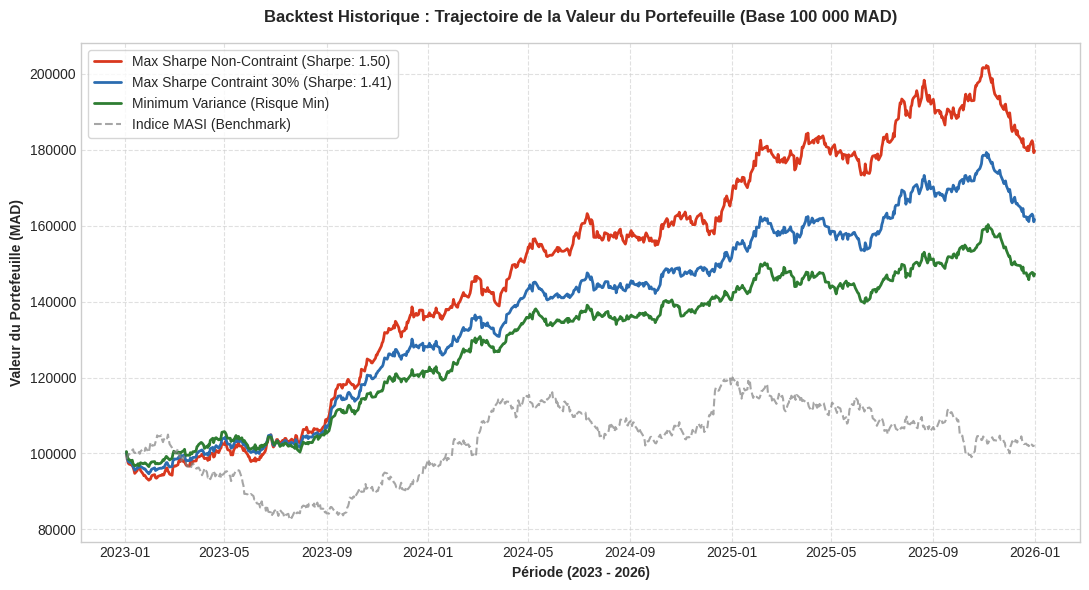

In [11]:
# =========================================================
# MODULE DE TEST AVANCÉ : HEATMAP DE CORRÉLATION & BACKTEST CUMULÉ
# =========================================================

# 1. VISUEL 4 : HEATMAP DE LA MATRICE DE CORRÉLATION
plt.figure(figsize=(8, 6))
matrice_corr = rendements_journaliers[tickers].corr()

sns.heatmap(matrice_corr, annot=True, fmt=".2f", cmap='Blues', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Coefficient de Corrélation de Pearson'})

plt.title('Matrice de Corrélation Croisée des Actifs (Bourse de Casablanca)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 2. VISUEL 5 : BACKTEST HISTORIQUE CUMULÉ (Capital Initial : 100 000 MAD)
capital_initial = 100000

# Calcul des rendements quotidiens des portefeuilles
ret_ms_unconstrained = rendements_journaliers[tickers].dot(poids_sharpe)
ret_ms_constrained = rendements_journaliers[tickers].dot(poids_max_30)
ret_mv = rendements_journaliers[tickers].dot(poids_min_var)
ret_masi = rendements_journaliers['MASI']

# Calcul de la valeur cumulée dans le temps
val_ms_unconstrained = capital_initial * (1 + ret_ms_unconstrained).cumprod()
val_ms_constrained = capital_initial * (1 + ret_ms_constrained).cumprod()
val_mv = capital_initial * (1 + ret_mv).cumprod()
val_masi = capital_initial * (1 + ret_masi).cumprod()

plt.figure(figsize=(11, 6))
plt.plot(val_ms_unconstrained.index, val_ms_unconstrained, label='Max Sharpe Non-Contraint (Sharpe: 1.50)', color='#D9381E', linewidth=2)
plt.plot(val_ms_constrained.index, val_ms_constrained, label='Max Sharpe Contraint 30% (Sharpe: 1.41)', color='#2B6CB0', linewidth=2)
plt.plot(val_mv.index, val_mv, label='Minimum Variance (Risque Min)', color='#2E7D32', linewidth=2)
plt.plot(val_masi.index, val_masi, label='Indice MASI (Benchmark)', color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

plt.title('Backtest Historique : Trajectoire de la Valeur du Portefeuille (Base 100 000 MAD)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Valeur du Portefeuille (MAD)', fontsize=10, fontweight='bold')
plt.xlabel('Période (2023 - 2026)', fontsize=10, fontweight='bold')
plt.legend(loc='upper left', frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()